In [1]:
import numpy as np
import matplotlib.pyplot as plt

# The Python implementation of the function above is rather slow
# We made a C++ library that implements the function above much faster
# To run this library one needs to load cpp_routines which will, in turn, 
# load a library routines_lib.so from the folder RewardCalc
# If the library file is not there the loader will attempt to run Makefile in RewardCalc
# The library function expected_reward_table is called in exactly the same way

import sys
sys.path.append('../RewardCalc')
from cpp_routines import *

In [2]:
# We have coded up a special C++ function that finds the minimal number of remaining presses
# For which it is more optimal to leave the current button and explore further
# For given number of wins and fails
# If no such number exists for the given process duration, the function returns 0

trans_table = optimal_transition_table(10, 10, 2000, prior=(1, 1))
print(trans_table)

[[   1    1    1    1    1    1    1    1    1    1]
 [   0    1    1    1    1    1    1    1    1    1]
 [   0   12    1    1    1    1    1    1    1    1]
 [   0   39    5    1    1    1    1    1    1    1]
 [   0   94   10    3    1    1    1    1    1    1]
 [   0  190   19    6    3    1    1    1    1    1]
 [   0  344   30   10    5    2    1    1    1    1]
 [   0  578   45   14    7    4    2    1    1    1]
 [   0  915   63   20    9    5    3    2    1    1]
 [   0 1385   86   27   13    7    5    3    2    1]]


In [3]:
run_time = 40
number_of_runs = 1000
button_prior = (1, 1)
policy_prior = (1, 1)

trial_record = record_full_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior, 
                                                                      policy_prior=policy_prior)
#Taking only wins and fails
trial_record = trial_record[:,:,[0,3]]

In [4]:
subjects = []
for record in trial_record:
    button_split = [record[record[:,0]==k,1] for k in np.unique(record[:,0])]
    decisions = [np.vstack([np.cumsum(elt),
                            np.arange(1,len(elt)+1)-np.cumsum(elt),
                            np.eye(1,M=len(elt),k=len(elt)-1)]).T for elt in button_split]
    decisions = np.concatenate(decisions)
    decisions = np.c_[decisions, np.arange(len(decisions))[::-1]][:-1]
    subjects.append(decisions)
    
decisions = np.concatenate(subjects)
decisions = decisions[np.lexsort((decisions[:,3], decisions[:,2], decisions[:,1], decisions[:,0]))].astype(int)

In [5]:
out1, out2 = np.unique(decisions[:,:2], axis=0, return_counts=True)
total_counts = np.c_[out1, out2]

In [6]:
total_counts[total_counts[:,0]<10]

array([[   0,    1, 3017],
       [   1,    0, 2872],
       [   1,    1,  978],
       [   2,    0, 1889],
       [   2,    1,  455],
       [   2,    2,   10],
       [   3,    0, 1430],
       [   3,    1,  315],
       [   3,    2,  106],
       [   4,    0, 1132],
       [   4,    1,  405],
       [   4,    2,  137],
       [   4,    3,    6],
       [   5,    0,  930],
       [   5,    1,  410],
       [   5,    2,   90],
       [   5,    3,    6],
       [   5,    4,    1],
       [   6,    0,  787],
       [   6,    1,  424],
       [   6,    2,   92],
       [   6,    3,   13],
       [   6,    4,    1],
       [   7,    0,  686],
       [   7,    1,  411],
       [   7,    2,  140],
       [   7,    3,   42],
       [   7,    4,    4],
       [   7,    5,    1],
       [   8,    0,  614],
       [   8,    1,  382],
       [   8,    2,  168],
       [   8,    3,   53],
       [   8,    4,   10],
       [   8,    5,    3],
       [   8,    6,    1],
       [   9,    0,  549],
 

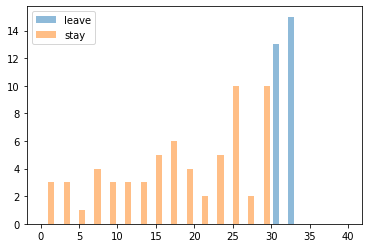

In [7]:
wins, fails = 6, 2
choise = decisions[np.logical_and(decisions[:,0]==wins,decisions[:,1]==fails)][:,2:]
leave = choise[choise[:,0]==1][:,1]
stay = choise[choise[:,0]==0][:,1]

plt.hist([leave, stay], alpha=0.5, label=["leave", "stay"], range=[0.0, 40.0], bins=20)
plt.legend(loc="upper left")
plt.show()